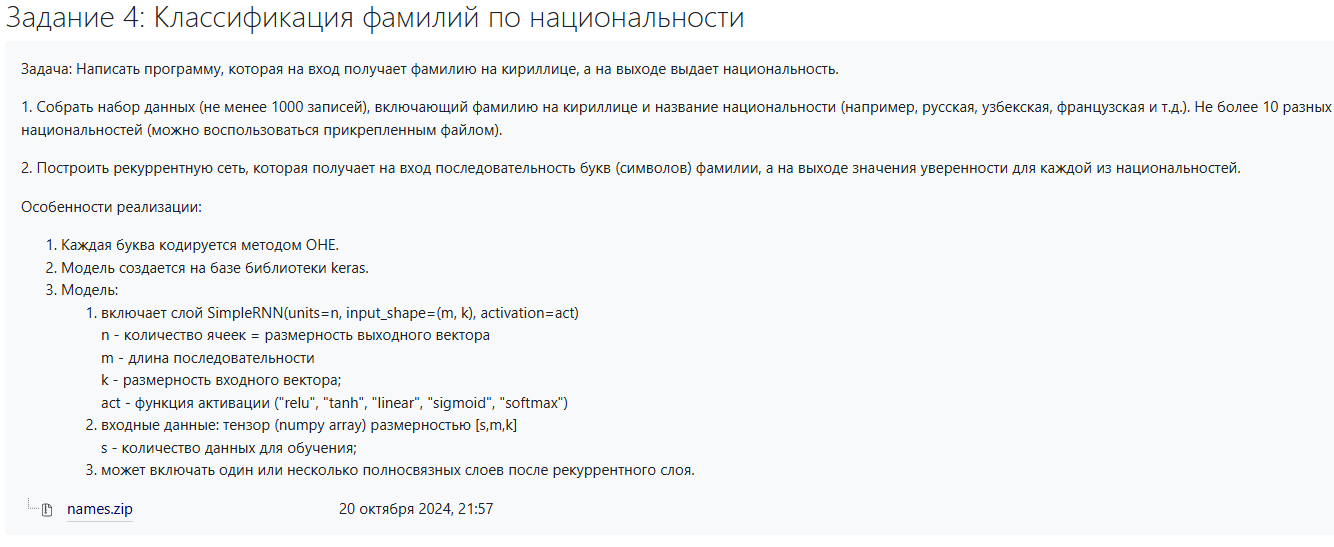

In [35]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout, GRU, LSTM
from tensorflow.keras.utils import to_categorical

# Фиксируем random seed для воспроизводимости результатов
np.random.seed(42)

In [14]:
import numpy as np

def predict_nationality(surnames):
    """
    Принимает массив фамилий на вход.
    Для каждой фамилии возвращает список из трёх наиболее вероятных
    национальностей и соответствующих вероятностей.

    Параметры
    ----------
    surnames : list[str] или tuple[str]
        Список фамилий для предсказания.

    Возвращает
    ----------
    results : list[list[tuple[str, float]]]
        Для каждой фамилии — список кортежей (национальность, вероятность),
        отсортированный по убыванию вероятности (топ-3).
    """
    # Если передали одну строку, оборачиваем в список для единообразия
    if isinstance(surnames, str):
        surnames = [surnames]

    # Предобработка всех имён и формирование батча
    x_input = np.stack([
        encode_name(surname, max_len, k, char_to_int)
        for surname in surnames
    ])  # форма: (n_samples, m, k)

    # Предсказание для всего батча сразу
    predictions = model.predict(x_input, verbose=0)  # форма: (n_samples, n_classes)

    results = []
    for row in predictions:
        # Индексы трёх наибольших вероятностей (по убыванию)
        top3_idx = np.argsort(row)[-3:][::-1]

        # Формируем список (класс, вероятность)
        top3 = [
            (label_encoder.classes_[i], float(row[i]))
            for i in top3_idx
        ]
        results.append(top3)

    return results

In [5]:
data_dir = 'names' # Путь к папке с файлами
data = []

# Чтение всех файлов .txt из папки
for filename in os.listdir(data_dir):
    if filename.endswith(".txt"):
        nationality = filename.split('.')[0] # Название файла = национальность
        filepath = os.path.join(data_dir, filename)
        
        with open(filepath, 'r', encoding='utf-8') as f:
            for line in f:
                name = line.strip()
                if name: # Пропускаем пустые строки
                    data.append([name, nationality])

df = pd.DataFrame(data, columns=['name', 'nationality'])

# Ограничение: не более 10 национальностей (берем топ-10 по количеству записей)
top_10_nationalities = df['nationality'].value_counts().nlargest(10).index
df = df[df['nationality'].isin(top_10_nationalities)].copy()

# Перемешиваем датасет
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Общее количество записей: {len(df)}")
print(f"Количество классов: {df['nationality'].nunique()}")
print(df['nationality'].value_counts())

Общее количество записей: 18891
Количество классов: 10
nationality
Russian     9408
English     3668
Arabic      2000
Japanese     991
German       724
Italian      709
Czech        519
Spanish      298
Dutch        297
French       277
Name: count, dtype: int64


In [6]:
# Преобразуем названия национальностей в числа
label_encoder = LabelEncoder()
df['label_encoded'] = label_encoder.fit_transform(df['nationality'])

# One-Hot Encoding для целевой переменной
num_classes = len(label_encoder.classes_)
y = to_categorical(df['label_encoded'], num_classes=num_classes)

print("Классы:", label_encoder.classes_)

Классы: ['Arabic' 'Czech' 'Dutch' 'English' 'French' 'German' 'Italian' 'Japanese'
 'Russian' 'Spanish']


In [9]:
# 1. Собираем весь алфавит из датасета
all_names = df['name'].tolist()
# Добавляем специальный символ для padding (заполнения)
vocab = sorted(list(set("".join(all_names))))
vocab = ['<PAD>'] + vocab 
char_to_int = {char: i for i, char in enumerate(vocab)}
int_to_char = {i: char for char, i in char_to_int.items()}

# 2. Определяем размерности (m и k из задания)
k = len(vocab) # Размерность входного вектора (размер алфавита)
max_len = max([len(name) for name in all_names]) # m - длина последовательности

print(f"Размер алфавита (k): {k}")
print(f"Максимальная длина фамилии (m): {max_len}")

# 3. Функция кодирования одной фамилии в тензор размерности (m, k)
def encode_name(name, max_len, k, char_to_int):
    # Преобразуем буквы в индексы
    seq = [char_to_int.get(char, 0) for char in name] # 0 - это <PAD>
    
    # Padding (дополнение до max_len)
    if len(seq) < max_len:
        seq = seq + [0] * (max_len - len(seq))
    else:
        seq = seq[:max_len]
        
    # One-Hot Encoding
    ohe = np.zeros((max_len, k))
    for i, val in enumerate(seq):
        ohe[i, val] = 1.0
    return ohe

# 4. Формируем входной тензор X размерности [s, m, k]
# s - количество данных для обучения (строк в датасете)
X = np.array([encode_name(name, max_len, k, char_to_int) for name in all_names])

print(f"Размерность входного тензора X: {X.shape} (s, m, k)")

print(vocab)

Размер алфавита (k): 79
Максимальная длина фамилии (m): 20
Размерность входного тензора X: (18891, 20, 79) (s, m, k)
['<PAD>', ' ', "'", ',', '-', '/', '1', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '\xa0', 'Á', 'É', 'ß', 'à', 'á', 'ä', 'ç', 'è', 'é', 'ê', 'ì', 'í', 'ñ', 'ò', 'ó', 'ö', 'ù', 'ú', 'ü']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (15112, 20, 79), Test shape: (3779, 20, 79)


# 1 вариант
орегинал

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_3 (SimpleRNN)        │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5892 - loss: 1.3308 - val_accuracy: 0.6487 - val_loss: 1.1223
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6801 - loss: 1.0420 - val_accuracy: 0.7129 - val_loss: 0.9491
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7177 - loss: 0.9169 - val_accuracy: 0.7231 - val_loss: 0.8814
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7364 - loss: 0.8472 - val_accuracy: 0.7469 - val_loss: 0.8029
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7575 - loss: 0.7831 - val_accuracy: 0.7416 - val_loss: 0.8153
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7716 - loss: 0.7328 - val_accuracy: 0.7638 - val_loss: 0.7490
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7815 - loss: 0.6944 - val_accuracy: 0.7701 - val_loss: 0.7379
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7896 - loss: 0.6691 - val_accuracy: 0.

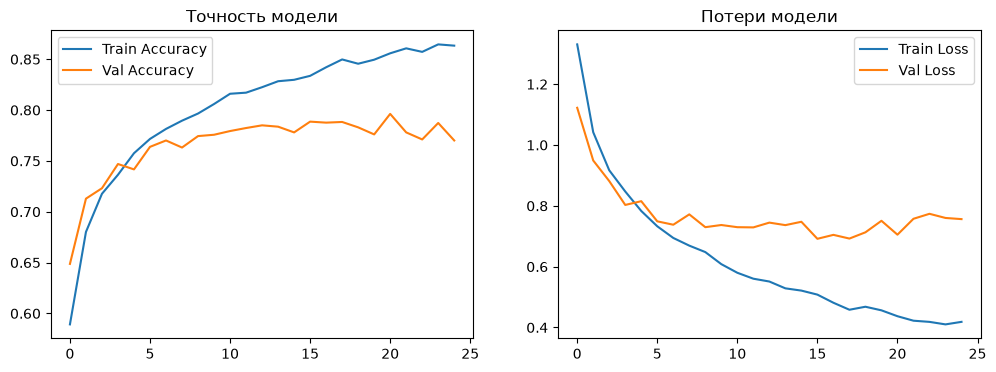

Иванов
  German: 0.5169
  Dutch: 0.2736
  French: 0.1079
Smith
  English: 0.4729
  Czech: 0.2951
  German: 0.1126
Müller
  German: 0.9395
  Dutch: 0.0318
  English: 0.0221
Kim
  English: 0.5112
  Czech: 0.2223
  Russian: 0.1794


In [18]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 2 вариант
n = 128 -> 32

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_4 (SimpleRNN)        │ (None, 32)             │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,346 (24.79 KB)

 Trainable params: 6,346 (24.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5354 - loss: 1.4846 - val_accuracy: 0.5921 - val_loss: 1.2505
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6158 - loss: 1.2183 - val_accuracy: 0.6179 - val_loss: 1.1859
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6510 - loss: 1.1453 - val_accuracy: 0.6434 - val_loss: 1.1156
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6733 - loss: 1.0824 - val_accuracy: 0.6699 - val_loss: 1.0638
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6878 - loss: 1.0266 - val_accuracy: 0.6824 - val_loss: 1.0149
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7057 - loss: 0.9772 - val_accuracy: 0.6973 - val_loss: 0.9625
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7176 - loss: 0.9345 - val_accuracy: 0.7142 - val_loss: 0.9179
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7312 - loss: 0.8911 - val_accuracy: 0.

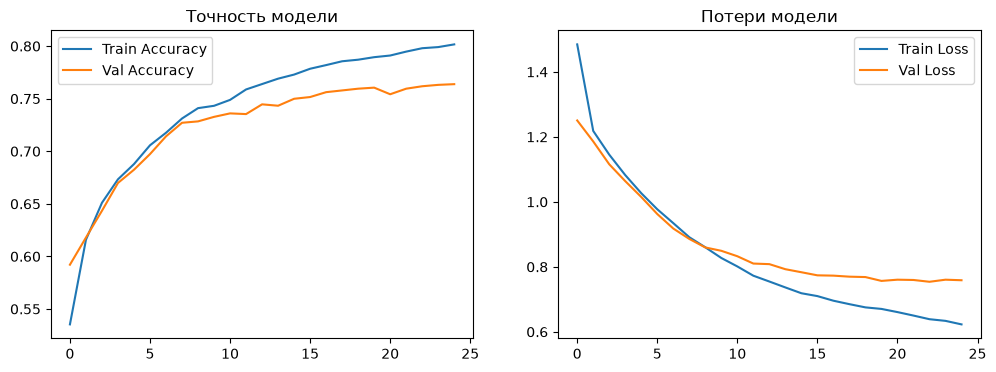

Иванов
  Russian: 0.9763
  English: 0.0163
  German: 0.0025
Smith
  English: 0.6186
  German: 0.1747
  Russian: 0.0688
Müller
  German: 0.6237
  English: 0.2717
  Czech: 0.0484
Kim
  Japanese: 0.9363
  English: 0.0328
  Czech: 0.0158


In [19]:
# Параметры модели из задания
n = 32 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 3 вариант
n = 128 -> 512

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_5 (SimpleRNN)        │ (None, 512)            │       303,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 336,586 (1.28 MB)

 Trainable params: 336,586 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5880 - loss: 1.3383 - val_accuracy: 0.5938 - val_loss: 1.2902
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6355 - loss: 1.1991 - val_accuracy: 0.6570 - val_loss: 1.0934
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6620 - loss: 1.1123 - val_accuracy: 0.6494 - val_loss: 1.1112
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6641 - loss: 1.0915 - val_accuracy: 0.6444 - val_loss: 1.1510
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6762 - loss: 1.0537 - val_accuracy: 0.6722 - val_loss: 1.0196
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6933 - loss: 1.0098 - val_accuracy: 0.6778 - val_loss: 1.0471
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7007 - loss: 0.9717 - val_accuracy: 0.7115 - val_loss: 0.9331
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7078 - loss: 0.9651 - val_accu

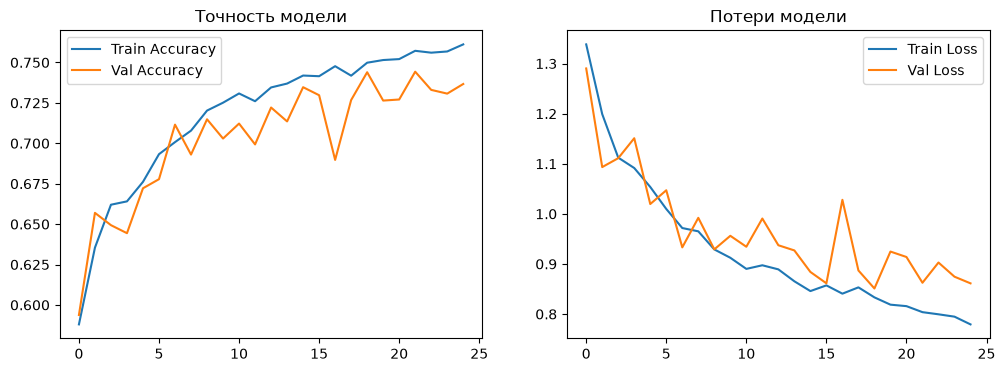

Иванов
  Arabic: 0.7828
  English: 0.1105
  Russian: 0.0271
Smith
  English: 0.5749
  German: 0.1873
  Italian: 0.0797
Müller
  German: 0.9422
  English: 0.0315
  Czech: 0.0161
Kim
  Japanese: 0.9673
  Czech: 0.0174
  English: 0.0077


In [ ]:
# Параметры модели из задания
n = 512 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 4 вариант
act = tanh -> sigmoid

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_17 (SimpleRNN)       │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.4825 - loss: 1.6900 - val_accuracy: 0.4985 - val_loss: 1.6058
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4987 - loss: 1.6377 - val_accuracy: 0.4985 - val_loss: 1.6029
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4999 - loss: 1.6206 - val_accuracy: 0.4985 - val_loss: 1.6014
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4996 - loss: 1.6160 - val_accuracy: 0.4985 - val_loss: 1.6012
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4998 - loss: 1.6159 - val_accuracy: 0.4985 - val_loss: 1.6022
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4998 - loss: 1.6145 - val_accuracy: 0.4985 - val_loss: 1.6024
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4998 - loss: 1.6088 - val_accuracy: 0.4985 - val_loss: 1.6006
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4998 - loss: 1.6044 - val_accuracy: 0.

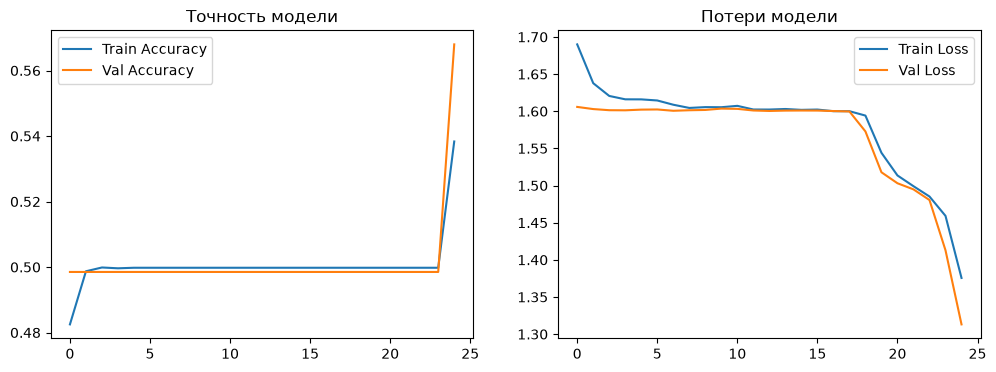

Иванов
  English: 0.3146
  Arabic: 0.1975
  Russian: 0.1830
Smith
  English: 0.3137
  Arabic: 0.1957
  Russian: 0.1882
Müller
  English: 0.3144
  Arabic: 0.1971
  Russian: 0.1844
Kim
  English: 0.3146
  Arabic: 0.1975
  Russian: 0.1830


In [37]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'sigmoid' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 5 вариант
act = tanh -> softsign

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_7 (SimpleRNN)        │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5511 - loss: 1.4236 - val_accuracy: 0.5812 - val_loss: 1.2592
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6173 - loss: 1.2137 - val_accuracy: 0.6451 - val_loss: 1.1462
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6621 - loss: 1.0853 - val_accuracy: 0.6388 - val_loss: 1.1159
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6830 - loss: 1.0174 - val_accuracy: 0.6642 - val_loss: 1.0328
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7098 - loss: 0.9541 - val_accuracy: 0.7139 - val_loss: 0.9286
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7398 - loss: 0.8525 - val_accuracy: 0.7337 - val_loss: 0.8473
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7673 - loss: 0.7683 - val_accuracy: 0.7456 - val_loss: 0.8205
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7847 - loss: 0.7069 - val_accuracy: 0.

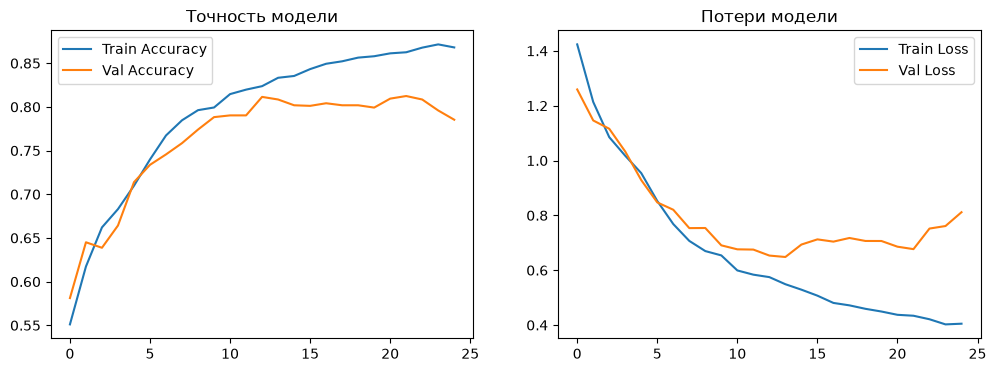

Иванов
  Spanish: 0.5695
  Arabic: 0.1622
  Italian: 0.0748
Smith
  English: 0.7219
  German: 0.1168
  Czech: 0.0701
Müller
  German: 0.8777
  Dutch: 0.0906
  Russian: 0.0121
Kim
  Czech: 0.3089
  Russian: 0.2898
  English: 0.1369


In [22]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'softsign' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 6 вариант
Убрал промежуточные слои

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_8 (SimpleRNN)        │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6049 - loss: 1.2826 - val_accuracy: 0.6669 - val_loss: 1.0742
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6867 - loss: 1.0155 - val_accuracy: 0.6699 - val_loss: 1.0060
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7042 - loss: 0.9353 - val_accuracy: 0.6894 - val_loss: 0.9504
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7285 - loss: 0.8585 - val_accuracy: 0.7023 - val_loss: 0.8953
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7515 - loss: 0.7930 - val_accuracy: 0.7248 - val_loss: 0.8524
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7664 - loss: 0.7374 - val_accuracy: 0.7119 - val_loss: 0.8745
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7809 - loss: 0.6969 - val_accuracy: 0.7552 - val_loss: 0.7480
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7887 - loss: 0.6682 - val_accuracy: 0.

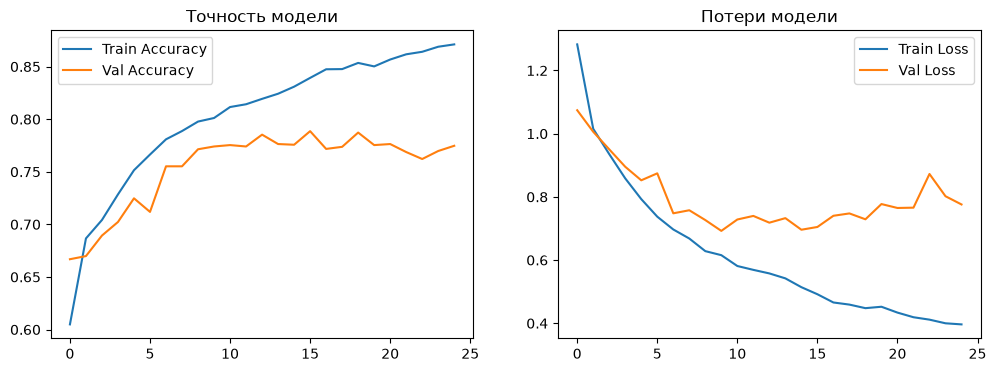

Иванов
  Russian: 0.9377
  Japanese: 0.0486
  Czech: 0.0059
Smith
  English: 0.5217
  German: 0.1706
  Dutch: 0.1601
Müller
  German: 0.9834
  Dutch: 0.0131
  English: 0.0016
Kim
  Japanese: 0.6635
  Czech: 0.1785
  English: 0.0824


In [23]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 7 вариант
Оставил 1 полносвязный слой на 64

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_10 (SimpleRNN)       │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5963 - loss: 1.2724 - val_accuracy: 0.6652 - val_loss: 1.1068
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6984 - loss: 0.9799 - val_accuracy: 0.7125 - val_loss: 0.9296
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7345 - loss: 0.8553 - val_accuracy: 0.7324 - val_loss: 0.8462
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7595 - loss: 0.7637 - val_accuracy: 0.7483 - val_loss: 0.8070
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7767 - loss: 0.6973 - val_accuracy: 0.7516 - val_loss: 0.7748
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.6426 - val_accuracy: 0.7708 - val_loss: 0.7312
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8098 - loss: 0.5882 - val_accuracy: 0.7714 - val_loss: 0.7292
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8201 - loss: 0.5479 - val_accuracy: 0.

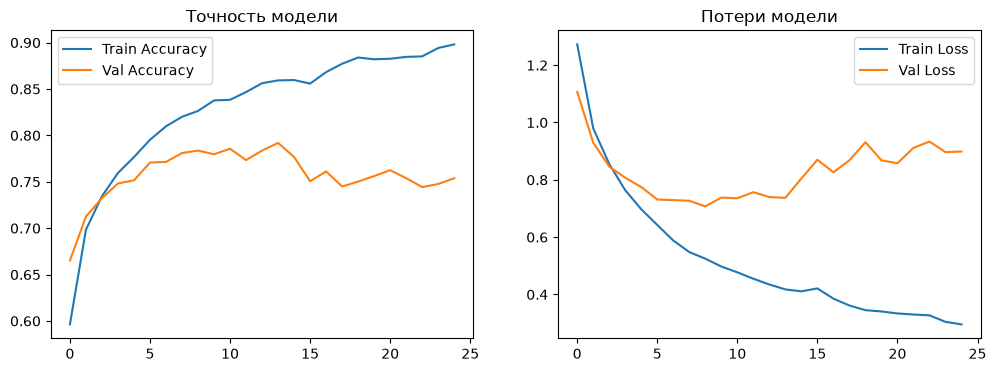

Иванов
  Japanese: 0.9597
  English: 0.0135
  Spanish: 0.0114
Smith
  English: 0.8135
  German: 0.0895
  Czech: 0.0609
Müller
  German: 0.9900
  Dutch: 0.0055
  Russian: 0.0022
Kim
  Japanese: 0.9969
  Russian: 0.0012
  Czech: 0.0011


In [25]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 8 вариант
loss = categorical_crossentropy -> kl_divergence

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_12 (SimpleRNN)       │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5847 - loss: 1.3282 - val_accuracy: 0.6728 - val_loss: 1.0763
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6898 - loss: 1.0265 - val_accuracy: 0.7096 - val_loss: 0.9590
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7189 - loss: 0.9196 - val_accuracy: 0.7135 - val_loss: 0.8950
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7408 - loss: 0.8461 - val_accuracy: 0.7416 - val_loss: 0.8312
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7530 - loss: 0.7904 - val_accuracy: 0.7532 - val_loss: 0.7874
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7714 - loss: 0.7364 - val_accuracy: 0.7423 - val_loss: 0.8010
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7801 - loss: 0.6985 - val_accuracy: 0.7383 - val_loss: 0.7893
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7932 - loss: 0.6586 - val_accuracy: 0.

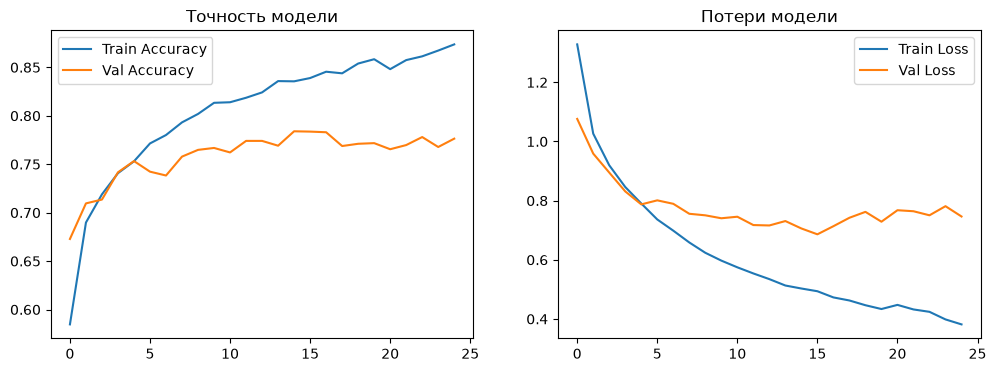

Иванов
  English: 0.5636
  French: 0.2272
  Arabic: 0.1164
Smith
  English: 0.9275
  Czech: 0.0293
  German: 0.0274
Müller
  German: 0.9813
  Dutch: 0.0112
  Czech: 0.0035
Kim
  Japanese: 0.9344
  English: 0.0256
  Czech: 0.0242


In [27]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='kl_divergence', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 9 вариант
loss = categorical_crossentropy -> categorical_hinge

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_14 (SimpleRNN)       │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5110 - loss: 0.7500 - val_accuracy: 0.4922 - val_loss: 0.7727
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5495 - loss: 0.6674 - val_accuracy: 0.5323 - val_loss: 0.6498
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5522 - loss: 0.6514 - val_accuracy: 0.4969 - val_loss: 0.6386
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5443 - loss: 0.6439 - val_accuracy: 0.5895 - val_loss: 0.6561
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5460 - loss: 0.6418 - val_accuracy: 0.5180 - val_loss: 0.6555
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5529 - loss: 0.6339 - val_accuracy: 0.5415 - val_loss: 0.6259
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5560 - loss: 0.6253 - val_accuracy: 0.4760 - val_loss: 0.6197
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5510 - loss: 0.6260 - val_accuracy: 0.

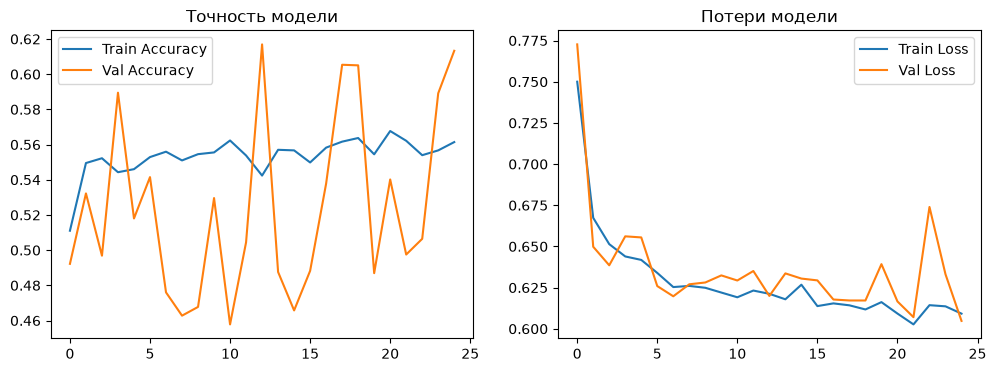

Иванов
  English: 0.1001
  Arabic: 0.1001
  Dutch: 0.1001
Smith
  English: 0.1001
  Arabic: 0.1001
  Dutch: 0.1001
Müller
  English: 0.1001
  Arabic: 0.1001
  Dutch: 0.1001
Kim
  English: 0.1001
  Arabic: 0.1001
  Dutch: 0.1001


In [29]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_hinge', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 10 вариант
dropout = 0.3 -> 0.5

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_15 (SimpleRNN)       │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5862 - loss: 1.3514 - val_accuracy: 0.6705 - val_loss: 1.0878
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6776 - loss: 1.0618 - val_accuracy: 0.6801 - val_loss: 1.0016
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7020 - loss: 0.9828 - val_accuracy: 0.6907 - val_loss: 0.9616
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7172 - loss: 0.9303 - val_accuracy: 0.7112 - val_loss: 0.9299
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7370 - loss: 0.8679 - val_accuracy: 0.7192 - val_loss: 0.8863
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7494 - loss: 0.8216 - val_accuracy: 0.7274 - val_loss: 0.8460
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7624 - loss: 0.7711 - val_accuracy: 0.7479 - val_loss: 0.7827
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7759 - loss: 0.7247 - val_accuracy: 0.

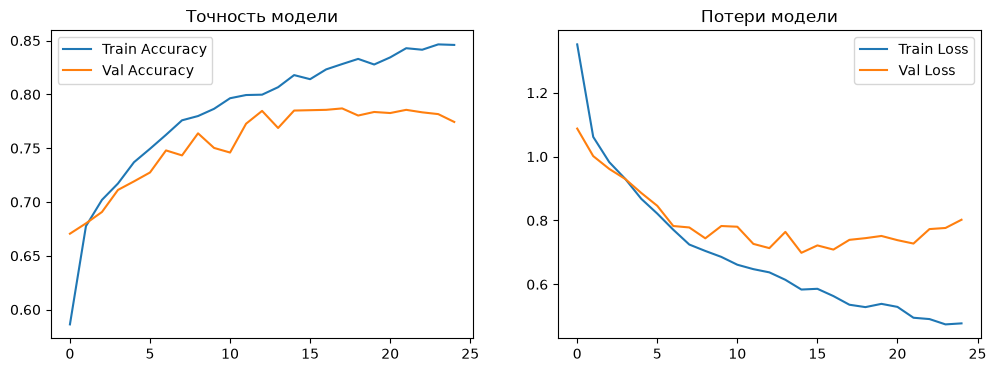

Иванов
  English: 0.4896
  Russian: 0.1925
  Czech: 0.1853
Smith
  English: 0.5888
  Czech: 0.2107
  Dutch: 0.1062
Müller
  German: 0.4889
  English: 0.2714
  Dutch: 0.0941
Kim
  Japanese: 0.8434
  Czech: 0.1426
  Russian: 0.0081


In [30]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 11 вариант
dropout = 0.3 -> 0.1

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_16 (SimpleRNN)       │ (None, 128)            │        26,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,530 (138.79 KB)

 Trainable params: 35,530 (138.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6062 - loss: 1.2713 - val_accuracy: 0.6639 - val_loss: 1.0784
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6899 - loss: 1.0068 - val_accuracy: 0.7043 - val_loss: 0.9530
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7288 - loss: 0.8841 - val_accuracy: 0.7248 - val_loss: 0.8759
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7497 - loss: 0.7972 - val_accuracy: 0.7317 - val_loss: 0.8470
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7692 - loss: 0.7290 - val_accuracy: 0.7311 - val_loss: 0.8208
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7862 - loss: 0.6769 - val_accuracy: 0.7397 - val_loss: 0.7981
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7987 - loss: 0.6354 - val_accuracy: 0.7688 - val_loss: 0.7357
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8083 - loss: 0.5989 - val_accuracy: 0.

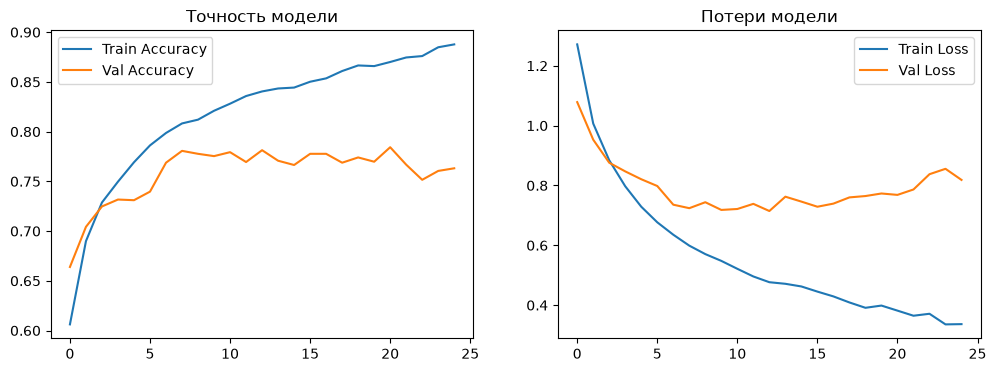

Иванов
  Spanish: 0.5029
  French: 0.2294
  Italian: 0.2064
Smith
  Czech: 0.2513
  Dutch: 0.2396
  English: 0.2208
Müller
  German: 0.8726
  Dutch: 0.0717
  French: 0.0463
Kim
  Japanese: 0.8148
  Czech: 0.0830
  Russian: 0.0368


In [31]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(SimpleRNN(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 12 вариант
rnm -> lstm

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │       106,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 115,402 (450.79 KB)

 Trainable params: 115,402 (450.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5422 - loss: 1.4491 - val_accuracy: 0.5809 - val_loss: 1.2748
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6360 - loss: 1.1492 - val_accuracy: 0.6642 - val_loss: 1.0587
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6800 - loss: 1.0180 - val_accuracy: 0.6818 - val_loss: 0.9955
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6942 - loss: 0.9562 - val_accuracy: 0.6986 - val_loss: 0.9486
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7054 - loss: 0.9102 - val_accuracy: 0.6980 - val_loss: 0.9254
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7263 - loss: 0.8544 - val_accuracy: 0.7225 - val_loss: 0.8748
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7428 - loss: 0.8169 - val_accuracy: 0.7370 - val_loss: 0.8256
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7613 - loss: 0.7693 - val_accuracy: 0

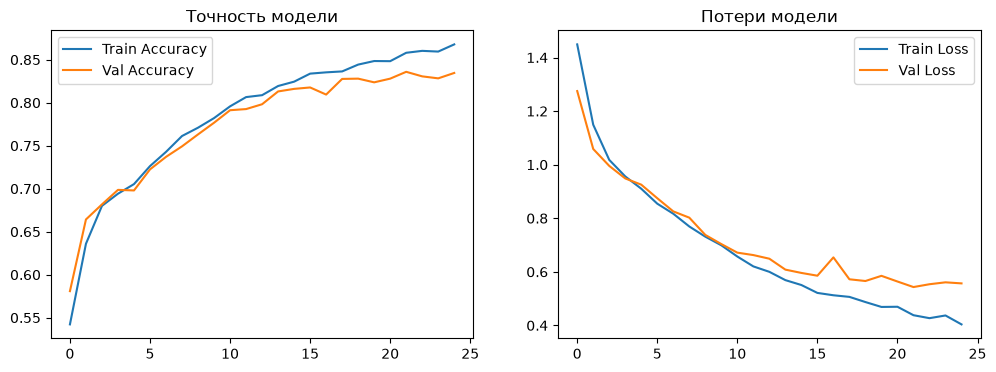

Иванов
  Russian: 0.6612
  Czech: 0.1186
  English: 0.0832
Smith
  Russian: 0.4831
  Czech: 0.1464
  English: 0.1225
Müller
  German: 0.9988
  Russian: 0.0005
  Dutch: 0.0003
Kim
  English: 0.3093
  Russian: 0.2798
  German: 0.1869


In [34]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(LSTM(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 13 вариант
rnm -> GRU

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 128)            │        80,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,162 (348.29 KB)

 Trainable params: 89,162 (348.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5242 - loss: 1.5214 - val_accuracy: 0.5809 - val_loss: 1.2508
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5926 - loss: 1.2199 - val_accuracy: 0.5921 - val_loss: 1.2027
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6168 - loss: 1.1745 - val_accuracy: 0.6414 - val_loss: 1.1327
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6681 - loss: 1.0648 - val_accuracy: 0.6838 - val_loss: 1.0197
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7001 - loss: 0.9616 - val_accuracy: 0.7006 - val_loss: 0.9436
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7157 - loss: 0.8993 - val_accuracy: 0.7145 - val_loss: 0.8812
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7376 - loss: 0.8319 - val_accuracy: 0.7483 - val_loss: 0.8053
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7612 - loss: 0.7669 - val_accuracy: 0

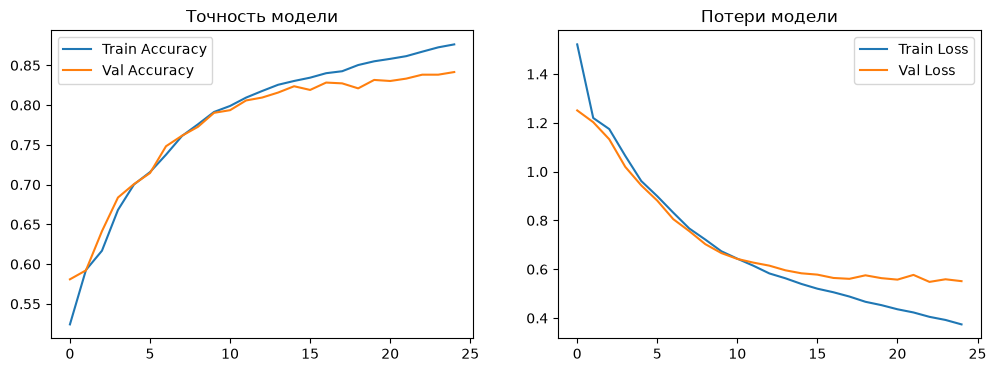

Иванов
  Arabic: 0.4436
  Russian: 0.2094
  English: 0.1804
Smith
  English: 0.7297
  German: 0.1407
  Russian: 0.0914
Müller
  German: 0.9989
  English: 0.0009
  Czech: 0.0001
Kim
  Arabic: 0.9983
  English: 0.0011
  Russian: 0.0005


In [36]:
# Параметры модели из задания
n = 128 # количество ячеек SimpleRNN
act = 'tanh' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(GRU(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")

# 14 вариант
Все лучшие параметры
n = 128 -> 32
act = tanh -> softsign
dropout = 0.3 -> 0.5
loss = categorical_crossentropy -> kl_divergence
rnm -> lstm

Model: "sequential_20"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │        14,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,098 (66.79 KB)

 Trainable params: 17,098 (66.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.4947 - loss: 1.6648 - val_accuracy: 0.4985 - val_loss: 1.3593
Epoch 2/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5718 - loss: 1.3080 - val_accuracy: 0.5888 - val_loss: 1.2398
Epoch 3/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5996 - loss: 1.2468 - val_accuracy: 0.5925 - val_loss: 1.2196
Epoch 4/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6045 - loss: 1.2140 - val_accuracy: 0.5968 - val_loss: 1.2002
Epoch 5/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6074 - loss: 1.1932 - val_accuracy: 0.6077 - val_loss: 1.1616
Epoch 6/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6326 - loss: 1.1302 - val_accuracy: 0.6761 - val_loss: 1.0557
Epoch 7/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6880 - loss: 1.0110 - val_accuracy: 0.6904 - val_loss: 0.9605
Epoch 8/25
189/189 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7014 - loss: 0.9563 - val_accuracy: 0.

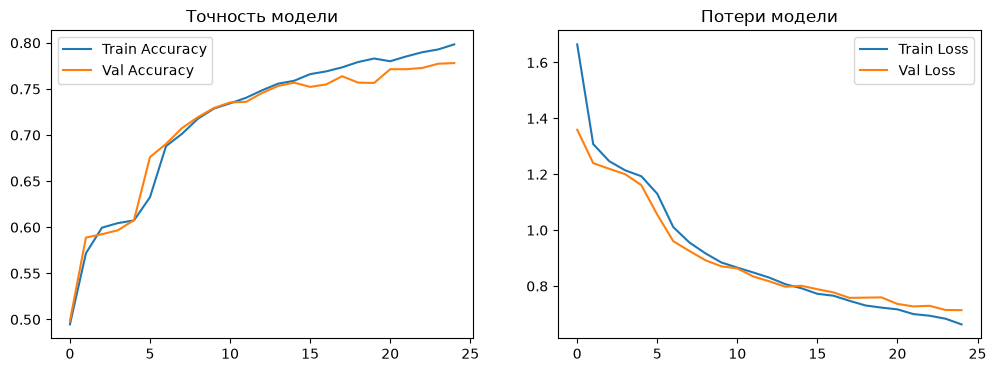

Иванов
  Arabic: 0.7683
  English: 0.1151
  Russian: 0.0406
Smith
  English: 0.5726
  Russian: 0.1523
  German: 0.1101
Müller
  English: 0.5312
  German: 0.2329
  Czech: 0.0586
Kim
  Arabic: 0.8245
  English: 0.0747
  Russian: 0.0417


In [38]:
# Параметры модели из задания
n = 32 # количество ячеек SimpleRNN
act = 'softsign' # функция активации для RNN

model = Sequential()

# 1. Рекуррентный слой SimpleRNN
# input_shape=(m, k)
model.add(LSTM(units=n, input_shape=(max_len, k), activation=act))

# 2. Полносвязные слои (один или несколько)
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.5)) # Для борьбы с переобучением

# 3. Выходной слой (количество нейронов = количество национальностей)
model.add(Dense(num_classes, activation='softmax'))

model.summary()

model.compile(optimizer='adam', 
              loss='kl_divergence', 
              metrics=['accuracy'])

# Обучение
history = model.fit(X_train, y_train, 
                    epochs=25, 
                    batch_size=64, 
                    validation_split=0.2, 
                    verbose=1)

# Оценка на тестовой выборке
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Точность на тестовой выборке: {test_acc:.4f}")

# Графики обучения
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Точность модели')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Потери модели')
plt.legend()
plt.show()

surnames = ["Иванов", "Smith", "Müller", "Kim"]
for surname, top3 in zip(surnames, predict_nationality(surnames)):
    print(surname)
    for nationality, prob in top3:
        print(f"  {nationality}: {prob:.4f}")